# Multi-input Deep Learning for News Classification

**Author:** Enrico Maineri

This project implements a reproducible multi-label news classifier using article text, Bag-of-Words vectors, and publication metadata. It documents the data pipeline, model architecture, training procedure, and evaluation on held-out data.


## Setup

In [1]:
import numpy as np, tensorflow as tf, random, string, zipfile, pickle as pk
from collections import Counter

SEED = 213
def set_seed(s=SEED):
    np.random.seed(s); tf.random.set_seed(s); random.seed(s)
set_seed()
print('TF version:', tf.__version__)

TF version: 2.21.0


## Data loading

The dataset (about 11,000 news items with 18 non-exclusive categories) was provided by the course *Machine Learning, Artificial Neural Networks and Deep Learning* (University of Milan) and is not redistributed in this repository. Place `input_data.pkl` (or `input_data.zip` containing it) in a `data/` folder next to the notebook. The cell stops with an explicit message if the file is missing or does not contain the expected fields.

In [2]:
from pathlib import Path

DATA_DIR = Path('data')
PKL_PATH = DATA_DIR / 'input_data.pkl'
ZIP_PATH = DATA_DIR / 'input_data.zip'

# The dataset is not distributed with this repository: place input_data.pkl
# (or input_data.zip containing it) in a data/ folder next to the notebook.
if not PKL_PATH.exists():
    if not ZIP_PATH.exists():
        raise FileNotFoundError(
            'Dataset not found. Place input_data.pkl (or input_data.zip) in a data/ folder '
            'next to this notebook. The dataset is not included in the repository.'
        )
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

# The archive is a pickle provided by the course: only load files from a trusted source.
with open(PKL_PATH, 'rb') as f:
    data = pk.load(f)

print('keys in archive:', list(data.keys()))

EXPECTED_KEYS = {'texts', 'years', 'months', 'labels'}
if not EXPECTED_KEYS.issubset(data):
    raise ValueError(
        f'This archive contains {sorted(data)}, not the news dataset used here '
        f'(expected keys {sorted(EXPECTED_KEYS)} plus a Bag-of-Words matrix). '
        'Use the dataset provided by the course.'
    )

texts  = data['texts']      # list: raw text of each news (headline + short description)
years  = data['years']      # list: publication year
months = data['months']     # list: publication month
Y = np.array(data['labels']).astype('float32')  # ndarray [N, K], multi-hot targets

import scipy.sparse as sp
_known = {'texts', 'years', 'months', 'labels'}
bow_key = [k for k in data.keys() if k not in _known][0]
bow_raw = data[bow_key]
if not sp.issparse(bow_raw):
    bow_raw = np.asarray(bow_raw, dtype='float32')
print('BoW key:', bow_key, '| BoW shape:', bow_raw.shape, '| sparse:', sp.issparse(bow_raw))

N, K = Y.shape
assert N == len(texts) == len(years) == len(months), "Input fields must have the same number of samples."
assert Y.ndim == 2 and np.isin(Y, [0, 1]).all(), "Labels must be a binary multi-hot matrix."
assert K == 18, f"Expected 18 categories, found {K}."
assert bow_raw.shape[0] == N, "BoW rows must align with news entries."
labels_per_item = Y.sum(axis=1)
positive_per_label = Y.sum(axis=0)
assert labels_per_item.min() == 2 and labels_per_item.max() == 3, "Expected 2-3 labels per news item."
assert positive_per_label.min() >= 1000 and positive_per_label.max() <= 4000, "Label support differs from the expected dataset range."
print(f'N = {N} news, K = {K} categories')
print(f'Labels per item: min={labels_per_item.min()}, max={labels_per_item.max()}, '
      f'mean={labels_per_item.mean():.2f}')
print(f'Positive samples per label: min={positive_per_label.min()}, max={positive_per_label.max()}')
print('example text:', texts[0][:100], '...')


keys in archive: ['texts', 'years', 'months', 'X_bow', 'labels']


BoW key: X_bow | BoW shape: (11000, 10000) | sparse: False
N = 11000 news, K = 18 categories
Labels per item: min=2.0, max=3.0, mean=2.27
Positive samples per label: min=1000.0, max=4000.0
example text: The 10 Most Beautiful Places in Croatia As one of Europe's most popular beach destinations and bless ...


# 1. Model choice

This is a **multi-label classification** task: each news item can belong to more than one of the 18 semantic categories. The model has three input branches:

- an Embedding and LSTM branch for variable-length text;
- a dense branch for the supplied Bag-of-Words (BoW) count vector;
- a metadata branch for publication year and month.

The branch representations are concatenated and passed to a shared classifier. The output has 18 independent sigmoid probabilities, one for each category, so multiple labels can be predicted for one article.


# 2. Input preprocessing

The archive supplies article text, a BoW count matrix, publication year and month, and a multi-hot target matrix. The pipeline prepares three model inputs:

1. **Text:** clean and tokenize each article, map tokens to a training-only vocabulary, then pad or truncate each sequence to 100 integer IDs.
2. **BoW:** remove terms occurring in fewer than three training documents and standardize retained count features using statistics fitted on training rows.
3. **Metadata:** one-hot encode year and month using encoders fitted on training rows.

The dataset is split before fitting any vocabulary or transformer. Validation and test rows are transformed using training-fitted preprocessing only. The labels already have the required multi-hot representation.


### 2.0 - Train / validation / test split (70 / 15 / 15)
The test set is used only once, at the end; the validation set is used for model selection and early stopping.

The split is random but reproducible. Standard stratification does not apply directly because each item has several labels, so the code prints per-label prevalence in each split to check that the distributions are similar.

In [3]:
from sklearn.model_selection import train_test_split
idx = np.arange(N)
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, random_state=SEED)
idx_val,   idx_test = train_test_split(idx_tmp, test_size=0.50, random_state=SEED)
print(f'train={len(idx_train)}  val={len(idx_val)}  test={len(idx_test)}')

# Compare positive-label prevalence across the three splits.
for split_name, split_idx in (("train", idx_train), ("validation", idx_val), ("test", idx_test)):
    prevalence = Y[split_idx].mean(axis=0)
    print(f"{split_name:10s}: mean labels/sample={Y[split_idx].sum(axis=1).mean():.2f}; "
          f"per-label prevalence range={prevalence.min():.3f}-{prevalence.max():.3f}")


train=7700  val=1650  test=1650
train     : mean labels/sample=2.27; per-label prevalence range=0.088-0.369
validation: mean labels/sample=2.29; per-label prevalence range=0.079-0.338
test      : mean labels/sample=2.27; per-label prevalence range=0.081-0.365


### 2.1 - Text cleaning
The logical steps that turn a raw text into word tokens: replace `--` with a space, split on whitespace, **remove punctuation**, keep only **alphabetic** tokens, **lowercase**.

In [4]:
def clean_text(t):
    t = t.replace('--', ' ')
    table = str.maketrans('', '', string.punctuation)
    words = [w.translate(table) for w in t.split()]
    words = [w.lower() for w in words if w.isalpha()]
    return words

docs = [clean_text(t) for t in texts]
print('cleaned example:', docs[0][:15])

cleaned example: ['the', 'most', 'beautiful', 'places', 'in', 'croatia', 'as', 'one', 'of', 'europes', 'most', 'popular', 'beach', 'destinations', 'and']


### 2.2 - Vocabulary for the text branch (training set only)

The vocabulary is built from training documents only. It retains words appearing in at least MIN_DF distinct training documents and is capped at MAX_VOCAB entries. Index 0 is reserved for padding and out-of-vocabulary words.


In [5]:
MIN_DF, MAX_VOCAB = 2, 10000
doc_freq, term_freq = Counter(), Counter()
for i in idx_train:
    for w in set(docs[i]): doc_freq[w]  += 1
    for w in docs[i]:      term_freq[w] += 1

kept = [w for w in doc_freq if doc_freq[w] >= MIN_DF]
kept = sorted(kept, key=lambda w: term_freq[w], reverse=True)[:MAX_VOCAB]
word2idx = {w: i + 1 for i, w in enumerate(kept)}   # 0 reserved for padding/OOV
V = len(word2idx)
print(f'vocabulary size V = {V}')

vocabulary size V = 10000


### 2.3 - Text branch input: integer sequences + padding
Each news becomes a sequence of word indices, **padded/truncated** to `MAXLEN = 100` (lengths range 1-100 in the data). Final shape `[N, 100]`, integer domain `{0, ..., V}` (0 = padding).

In [6]:
MAXLEN = 100
seqs  = [[word2idx[w] for w in d if w in word2idx] for d in docs]
X_seq = tf.keras.utils.pad_sequences(seqs, maxlen=MAXLEN, padding='post', truncating='post')
print('X_seq shape:', X_seq.shape, '| dtype:', X_seq.dtype)

X_seq shape: (11000, 100) | dtype: int32


### 2.4 - BoW branch input: frequency reduction and standardization

The archive provides a 10,000-dimensional Bag-of-Words count vector for each item. We retain terms appearing in at least MIN_DF_BOW training documents, then fit StandardScaler on training rows and apply that transformation to every split. After filtering, 7,732 of the 10,000 words are kept.


In [7]:
import scipy.sparse as sp
from sklearn.preprocessing import StandardScaler

MIN_DF_BOW = 3   # drop words occurring in fewer than 3 training documents (frequency-based reduction)

# document frequency per word, computed on the TRAINING rows only
bow_train = bow_raw[idx_train]
if sp.issparse(bow_train):
    df_bow = np.asarray((bow_train > 0).sum(axis=0)).ravel()
else:
    df_bow = (bow_train > 0).sum(axis=0)

keep_cols = np.where(df_bow >= MIN_DF_BOW)[0]
X_bow = bow_raw[:, keep_cols]
X_bow = X_bow.toarray() if sp.issparse(X_bow) else np.asarray(X_bow)
X_bow = X_bow.astype('float32')

scaler = StandardScaler().fit(X_bow[idx_train])
X_bow = scaler.transform(X_bow).astype('float32')
print('BoW reduced shape:', X_bow.shape, f'(kept {len(keep_cols)} of {bow_raw.shape[1]} words)')

BoW reduced shape: (11000, 7732) (kept 7732 of 10000 words)


### 2.5 - Metadata branch input: one-hot encoding

Year and month are categorical values, not continuous measurements. One-hot encoding represents each value as its own binary feature without implying a numerical distance between category IDs. Encoders are fitted only on training rows; an unseen value is safely represented by all-zero columns for that field.


In [8]:
from sklearn.preprocessing import OneHotEncoder
yr = np.array(years).reshape(-1, 1)
mo = np.array(months).reshape(-1, 1)
ohe_year  = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(yr[idx_train])
ohe_month = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(mo[idx_train])
X_meta = np.concatenate([ohe_year.transform(yr), ohe_month.transform(mo)], axis=1).astype('float32')
print('X_meta shape:', X_meta.shape)   # expected [N, 23]

X_meta shape: (11000, 23)


### 2.6 - Assemble the three inputs per split
The model receives a **list of three inputs** `[sequence, bow, metadata]`, with value domains: sequence in `{0,...,V}`, BoW standardized (real), metadata in `{0,1}`.

In [9]:
X_train = [X_seq[idx_train], X_bow[idx_train], X_meta[idx_train]]
X_val   = [X_seq[idx_val],   X_bow[idx_val],   X_meta[idx_val]]
X_test  = [X_seq[idx_test],  X_bow[idx_test],  X_meta[idx_test]]
Y_train, Y_val, Y_test = Y[idx_train], Y[idx_val], Y[idx_test]
print('shapes:', [a.shape for a in X_train], Y_train.shape)

shapes: [(7700, 100), (7700, 7732), (7700, 23)] (7700, 18)


# 3. Output and loss

The model outputs 18 independent probabilities using a sigmoid activation. Each estimates whether its category applies to the article. Because categories are not mutually exclusive, softmax would impose an unsuitable sum-to-one constraint.

The target matrix contains one binary value per sample and category. Binary cross-entropy is applied independently to each output and averaged across the batch and categories.


For a target vector $y \in \{0,1\}^K$ and predicted probabilities $p_k$, the per-sample binary cross-entropy is

$$
L(y,p) = -\frac{1}{K} \sum_{k=1}^{K} \left[y_k \log(p_k) + (1-y_k) \log(1-p_k)\right].
$$

Keras `binary_crossentropy` implements this independent-label objective for the sigmoid outputs.


# 4. Model configuration

This section builds the model, runs a small hyperparameter search scored on validation macro-F1, and trains the selected configuration with early stopping on the validation loss.

### 4.a - Model composition (pipeline)

Each input is processed by its own branch. The resulting vectors are concatenated and passed through a dense classification head.

~~~~
  Text [B,100]             BoW [B,D_BOW]          Metadata [B,23]
       |                         |                       |
  Embedding [B,100,E]      Dense(128)+BN+ReLU        identity
       |                         |                       |
  LSTM [B,256]              [B,128]                   [B,23]
       \_________________________|_______________________/
                                 |
                     Concatenate [B,407]
                                 |
                     Dense(256)+ReLU -> Dropout
                     Dense(64)+ReLU  -> Dropout
                     Dense(18)+Sigmoid
~~~~

D_BOW is the number of features remaining after training-set frequency filtering. The concatenated width is 407: 256 LSTM features, 128 BoW features, and 23 metadata features.


In [10]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Embedding, LSTM, Dense, Dropout,
                                     BatchNormalization, Activation, Concatenate)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.initializers import HeNormal

def build_model(emb_dim, hidden_sizes, dropout_rate, l2_reg):
    # Text branch: mask padding so it does not affect the LSTM state.
    in_seq = Input(shape=(MAXLEN,), name='text')
    x_t = Embedding(input_dim=V + 1, output_dim=emb_dim, mask_zero=True)(in_seq)
    x_t = LSTM(256)(x_t)   # LSTM hidden size fixed (not tuned)
    # BoW branch: project standardized counts to a compact representation.
    in_bow = Input(shape=(X_bow.shape[1],), name='bow')
    x_b = Dense(128, kernel_regularizer=l2(l2_reg), kernel_initializer=HeNormal())(in_bow)
    x_b = BatchNormalization()(x_b)
    x_b = Activation('relu')(x_b)
    # Metadata branch: concatenate the one-hot year and month features directly.
    in_meta = Input(shape=(X_meta.shape[1],), name='meta')
    # concatenation + dense head (number & size of hidden layers = hidden_sizes)
    c = Concatenate()([x_t, x_b, in_meta])
    for h in hidden_sizes:
        c = Dense(h, activation='relu', kernel_regularizer=l2(l2_reg), kernel_initializer=HeNormal())(c)
        c = Dropout(dropout_rate)(c)
    out = Dense(K, activation='sigmoid')(c)
    return Model(inputs=[in_seq, in_bow, in_meta], outputs=out)

set_seed()
demo = build_model(emb_dim=64, hidden_sizes=(256, 64), dropout_rate=0.5, l2_reg=1e-4)
demo.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ bow (InputLayer)    │ (None, 7732)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text (InputLayer)   │ (None, 100)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    989,824 │ bow[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 100, 64)   │    640,064 │ text[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 100)       │          0 │ text[0][0]        │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128)       │        512 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 256)       │    328,704 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meta (InputLayer)   │ (None, 23)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 407)       │          0 │ lstm[0][0],       │
│ (Concatenate)       │                   │            │ activation[0][0], │
│                     │                   │            │ meta[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │    104,448 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │     16,448 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 18)        │      1,170 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,081,170 (7.94 MB)

 Trainable params: 2,080,914 (7.94 MB)

 Non-trainable params: 256 (1.00 KB)

**Model architecture figure:** the following Matplotlib diagram shows the three input branches and their fusion.

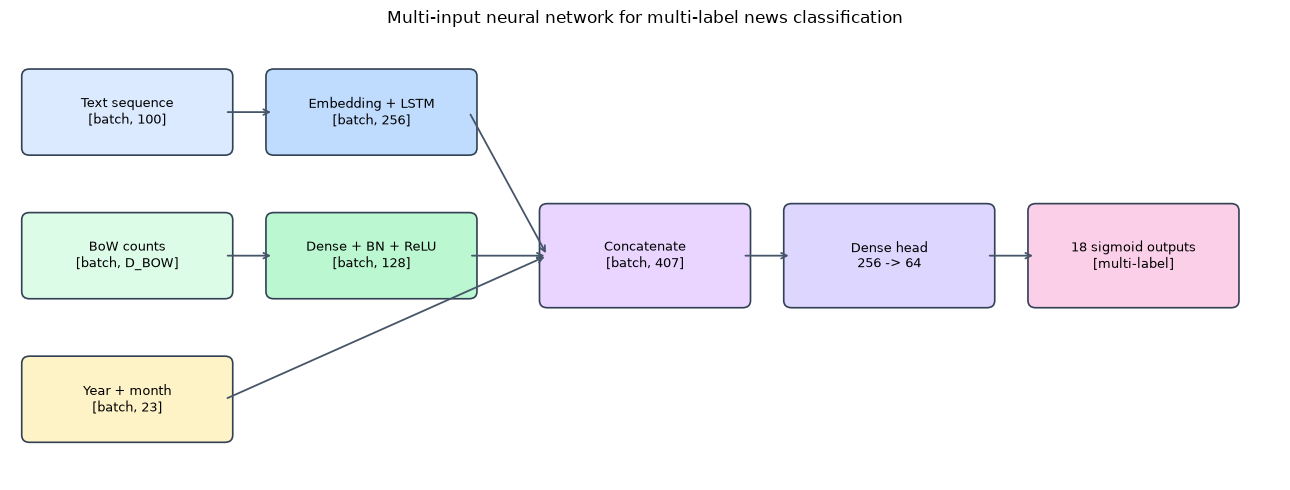

In [11]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Draw the architecture with Matplotlib so the figure does not depend on Graphviz.
fig, ax = plt.subplots(figsize=(13, 5))
ax.set_xlim(0, 13); ax.set_ylim(0, 5); ax.axis("off")

def box(x, y, w, h, label, color):
    patch = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08",
                           linewidth=1.2, edgecolor="#334155", facecolor=color)
    ax.add_patch(patch)
    ax.text(x + w/2, y + h/2, label, ha="center", va="center", fontsize=9)

box(0.2, 3.7, 2.0, 0.8, "Text sequence\n[batch, 100]", "#dbeafe")
box(2.7, 3.7, 2.0, 0.8, "Embedding + LSTM\n[batch, 256]", "#bfdbfe")
box(0.2, 2.1, 2.0, 0.8, "BoW counts\n[batch, D_BOW]", "#dcfce7")
box(2.7, 2.1, 2.0, 0.8, "Dense + BN + ReLU\n[batch, 128]", "#bbf7d0")
box(0.2, 0.5, 2.0, 0.8, "Year + month\n[batch, 23]", "#fef3c7")
box(5.5, 2.0, 2.0, 1.0, "Concatenate\n[batch, 407]", "#e9d5ff")
box(8.0, 2.0, 2.0, 1.0, "Dense head\n256 -> 64", "#ddd6fe")
box(10.5, 2.0, 2.0, 1.0, "18 sigmoid outputs\n[multi-label]", "#fbcfe8")
for y in (4.1, 2.5):
    ax.annotate("", xy=(5.5, 2.5), xytext=(4.7, y), arrowprops=dict(arrowstyle="->", color="#475569", lw=1.3))
ax.annotate("", xy=(5.5, 2.5), xytext=(2.2, 0.9), arrowprops=dict(arrowstyle="->", color="#475569", lw=1.3))
for y in (4.1, 2.5):
    ax.annotate("", xy=(2.7, y), xytext=(2.2, y), arrowprops=dict(arrowstyle="->", color="#475569", lw=1.3))
ax.annotate("", xy=(8.0, 2.5), xytext=(7.5, 2.5), arrowprops=dict(arrowstyle="->", color="#475569", lw=1.3))
ax.annotate("", xy=(10.5, 2.5), xytext=(10.0, 2.5), arrowprops=dict(arrowstyle="->", color="#475569", lw=1.3))
ax.set_title("Multi-input neural network for multi-label news classification", fontsize=12)
plt.tight_layout()
plt.show()


### 4.b - Optimization and model selection

The model uses Adam with learning rate 1e-3, gradient clipping, He initialization for dense layers, L2 regularization, dropout and early stopping. To keep the search fast, it compares eight configurations (embedding dimension, dense-head widths and dropout rate) trained for 5 epochs on a random subset of 3,000 training items, scoring each one by validation macro-F1. The best configuration is then retrained on the full training split.

In [12]:
import itertools
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import f1_score

# Vary the main capacity and regularization choices while keeping the search small.
param_grid = {
    'emb_dim':      [32, 64],                  # tuned (embedding dimension)
    'hidden_sizes': [(256, 64), (128, 64)],    # tuned (size of MLP hidden layers)
    'dropout_rate': [0.3, 0.5],                # tuned (dropout rate)
    'l2_reg':       [1e-4],
    'batch_size':   [256],
    'patience':     [2],
    'clipvalue':    [1.0],
}

SUBSET, EPOCHS_SEARCH = 3000, 5   # subset + few epochs to stay within the time budget
# Sample training rows rather than assuming the first rows are representative.
rng = np.random.default_rng(SEED)
subset_idx = rng.choice(len(Y_train), size=min(SUBSET, len(Y_train)), replace=False)
Xs = [a[subset_idx] for a in X_train]
Ys = Y_train[subset_idx]

keys = list(param_grid.keys())
best_f1, best_cfg = -1.0, None
for values in itertools.product(*[param_grid[k] for k in keys]):
    cfg = dict(zip(keys, values))
    tf.keras.backend.clear_session(); set_seed()
    m = build_model(cfg['emb_dim'], cfg['hidden_sizes'], cfg['dropout_rate'], cfg['l2_reg'])
    m.compile(optimizer=Adam(learning_rate=1e-3, clipvalue=cfg['clipvalue']), loss='binary_crossentropy')
    m.fit(Xs, Ys, epochs=EPOCHS_SEARCH, batch_size=cfg['batch_size'], verbose=0)
    f1 = f1_score(Y_val, (m.predict(X_val, verbose=0) >= 0.5).astype(int), average='macro', zero_division=0)
    print(f"emb_dim={cfg['emb_dim']}, hidden_sizes={cfg['hidden_sizes']}, dropout={cfg['dropout_rate']} -> val macro-F1={f1:.4f}")
    if f1 > best_f1: best_f1, best_cfg = f1, cfg

print('Best config:', best_cfg, '| val macro-F1:', round(best_f1, 4))


emb_dim=32, hidden_sizes=(256, 64), dropout=0.3 -> val macro-F1=0.2295


emb_dim=32, hidden_sizes=(256, 64), dropout=0.5 -> val macro-F1=0.0658


emb_dim=32, hidden_sizes=(128, 64), dropout=0.3 -> val macro-F1=0.1592


emb_dim=32, hidden_sizes=(128, 64), dropout=0.5 -> val macro-F1=0.0365


emb_dim=64, hidden_sizes=(256, 64), dropout=0.3 -> val macro-F1=0.2278


emb_dim=64, hidden_sizes=(256, 64), dropout=0.5 -> val macro-F1=0.0664


emb_dim=64, hidden_sizes=(128, 64), dropout=0.3 -> val macro-F1=0.1635


emb_dim=64, hidden_sizes=(128, 64), dropout=0.5 -> val macro-F1=0.0370
Best config: {'emb_dim': 32, 'hidden_sizes': (256, 64), 'dropout_rate': 0.3, 'l2_reg': 0.0001, 'batch_size': 256, 'patience': 2, 'clipvalue': 1.0} | val macro-F1: 0.2295


**Final training.** The best configuration is retrained on the full training set, with early stopping on the validation loss. This `model` is the one evaluated on the test set in Section 5.

In [13]:
tf.keras.backend.clear_session(); set_seed()
model = build_model(best_cfg['emb_dim'], best_cfg['hidden_sizes'],
                    best_cfg['dropout_rate'], best_cfg['l2_reg'])
model.compile(optimizer=Adam(learning_rate=1e-3, clipvalue=best_cfg['clipvalue']),
              loss='binary_crossentropy', metrics=['binary_accuracy'])
early = EarlyStopping(monitor='val_loss', patience=best_cfg['patience'], restore_best_weights=True)

EPOCHS = 10
history = model.fit(X_train, Y_train, validation_data=(X_val, Y_val),
                    epochs=EPOCHS, batch_size=best_cfg['batch_size'], callbacks=[early], verbose=2)

Epoch 1/10


31/31 - 17s - 564ms/step - binary_accuracy: 0.7878 - loss: 0.5668 - val_binary_accuracy: 0.8775 - val_loss: 0.4284


Epoch 2/10


31/31 - 20s - 645ms/step - binary_accuracy: 0.8804 - loss: 0.3934 - val_binary_accuracy: 0.8968 - val_loss: 0.3398


Epoch 3/10


31/31 - 20s - 650ms/step - binary_accuracy: 0.9226 - loss: 0.2649 - val_binary_accuracy: 0.9153 - val_loss: 0.2976


Epoch 4/10


31/31 - 20s - 642ms/step - binary_accuracy: 0.9609 - loss: 0.1680 - val_binary_accuracy: 0.9220 - val_loss: 0.3169


Epoch 5/10


31/31 - 21s - 692ms/step - binary_accuracy: 0.9809 - loss: 0.1157 - val_binary_accuracy: 0.9223 - val_loss: 0.3402


**Learning curves** (training vs validation loss)

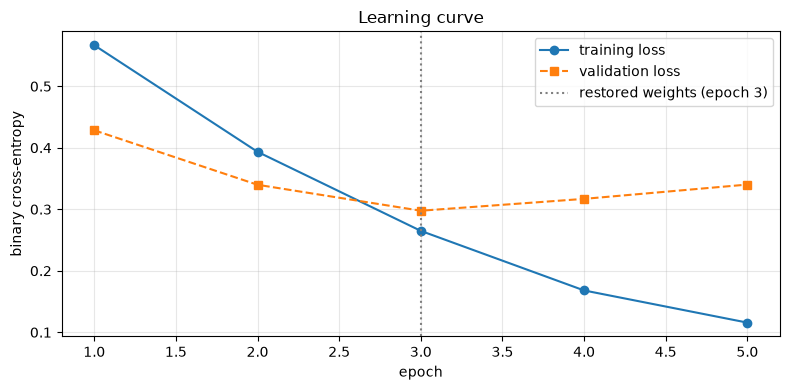

In [14]:
epochs = np.arange(1, len(history.history['loss']) + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(epochs, history.history['loss'], marker='o', label='training loss')
ax.plot(epochs, history.history['val_loss'], marker='s', linestyle='--', label='validation loss')
best_epoch = int(np.argmin(history.history['val_loss'])) + 1
ax.axvline(best_epoch, color='grey', linestyle=':', label=f'restored weights (epoch {best_epoch})')
ax.set(xlabel='epoch', ylabel='binary cross-entropy', title='Learning curve')
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

When the validation loss stops decreasing while the training loss keeps falling, the model starts to overfit; early stopping restores the weights from the epoch with the lowest validation loss (dotted line).

# 5. Model evaluation

The final model is evaluated on the held-out test split, which was not used for preprocessing, hyperparameter selection or early stopping.

We report micro-F1 and macro-F1. Micro-F1 pools all label decisions and is driven more by frequent categories; macro-F1 averages the F1 of each category, giving every category equal weight.

Predictions are first converted to labels with the standard 0.5 threshold; Section 5.3 then selects the threshold on validation data.

In [15]:
from sklearn.metrics import f1_score

Y_prob = model.predict(X_test, batch_size=512, verbose=0)
Y_pred = (Y_prob >= 0.5).astype(int)

f1_micro = f1_score(Y_test, Y_pred, average='micro', zero_division=0)
f1_macro = f1_score(Y_test, Y_pred, average='macro', zero_division=0)
print(f'Test F1 (micro): {f1_micro:.4f}')
print(f'Test F1 (macro): {f1_macro:.4f}')

Test F1 (micro): 0.6118
Test F1 (macro): 0.5223


### 5.1 - Results per category

The averages can hide weak categories, so we also report precision, recall and F1 for each of the 18 labels, at the fixed 0.5 threshold. The category names are not included in the archive, so labels are identified by their column index.

label  support  precision   recall     F1
    1      160      1.000    0.175  0.298
    3      160      0.970    0.200  0.332
    0      157      0.833    0.223  0.352
    8      141      0.914    0.227  0.364
    5      157      0.872    0.261  0.402
   15      141      0.889    0.284  0.430
    2      157      0.785    0.325  0.459
   16      149      0.870    0.315  0.463
   14      144      0.938    0.312  0.469
    6      164      0.873    0.335  0.485
    7      290      0.847    0.345  0.490
   13      150      0.806    0.360  0.498
   11      133      0.790    0.481  0.598
   12      274      0.834    0.551  0.664
    4      144      0.967    0.611  0.749
   17      312      0.813    0.724  0.766
   10      312      0.788    0.763  0.775
    9      603      0.817    0.801  0.809


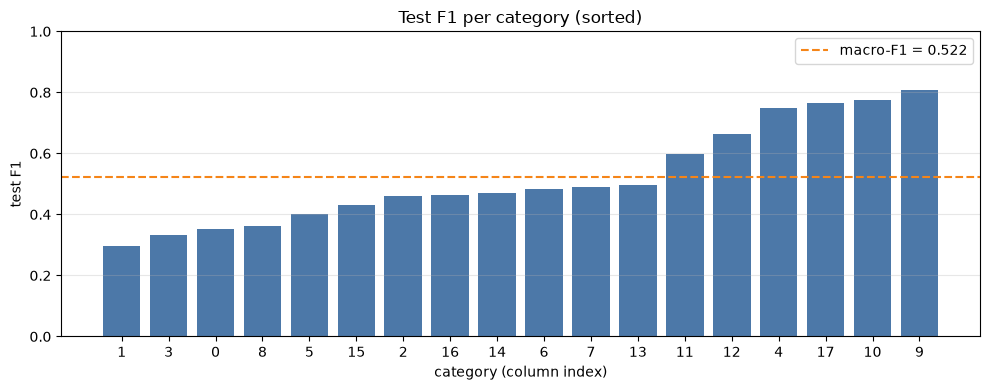

In [16]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1_per_label, support = precision_recall_fscore_support(
    Y_test, Y_pred, average=None, zero_division=0
)
order = np.argsort(f1_per_label)
print(f"{'label':>5} {'support':>8} {'precision':>10} {'recall':>8} {'F1':>6}")
for k in order:
    print(f"{k:>5} {int(support[k]):>8} {precision[k]:>10.3f} {recall[k]:>8.3f} {f1_per_label[k]:>6.3f}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([str(k) for k in order], f1_per_label[order], color='#4C78A8')
ax.axhline(f1_macro, color='#F58518', linestyle='--', label=f'macro-F1 = {f1_macro:.3f}')
ax.set(xlabel='category (column index)', ylabel='test F1', ylim=(0, 1),
       title='Test F1 per category (sorted)')
ax.grid(axis='y', alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

### 5.2 - Comparison with a classical baseline

To check whether the neural network adds value, we compare it with a simpler model: one logistic regression per category trained only on the standardized BoW features. Its regularization strength `C` is chosen on the validation set, exactly like the network's hyperparameters, and it is evaluated once on the same test set with the same 0.5 threshold. A trivial reference that always predicts the most frequent categories is also shown.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# Choose C on validation macro-F1 (the test set is not used for this choice).
best_c, best_val_f1, baseline = None, -1.0, None
for c in (0.01, 0.1, 1.0):
    candidate = OneVsRestClassifier(LogisticRegression(C=c, max_iter=2000), n_jobs=-1)
    candidate.fit(X_bow[idx_train], Y_train)
    val_f1 = f1_score(Y_val, candidate.predict(X_bow[idx_val]), average='macro', zero_division=0)
    print(f'logistic regression C={c}: validation macro-F1 = {val_f1:.4f}')
    if val_f1 > best_val_f1:
        best_c, best_val_f1, baseline = c, val_f1, candidate

baseline_pred = baseline.predict(X_bow[idx_test])

# Trivial reference: predict the categories that are positive for most training items.
frequent = (Y_train.mean(axis=0) >= np.sort(Y_train.mean(axis=0))[-3]).astype(int)
frequent_pred = np.tile(frequent, (len(Y_test), 1))

rows = {
    'most frequent categories': frequent_pred,
    f'logistic regression on BoW (C={best_c})': baseline_pred,
    'multi-input neural network': Y_pred,
}
print(f"\n{'model':45s} {'micro-F1':>9} {'macro-F1':>9}")
for name, pred in rows.items():
    print(f"{name:45s} {f1_score(Y_test, pred, average='micro', zero_division=0):>9.4f} "
          f"{f1_score(Y_test, pred, average='macro', zero_division=0):>9.4f}")

logistic regression C=0.01: validation macro-F1 = 0.5641


logistic regression C=0.1: validation macro-F1 = 0.5819


logistic regression C=1.0: validation macro-F1 = 0.5930

model                                          micro-F1  macro-F1
most frequent categories                         0.2683    0.0622
logistic regression on BoW (C=1.0)               0.6470    0.6200
multi-input neural network                       0.6118    0.5223


**Reading the comparison.** At the fixed 0.5 threshold the simple logistic regression on BoW features scores higher than the neural network (test macro-F1 ≈ 0.62 vs ≈ 0.52). The per-category table in 5.1 shows why: the network is very precise (precision mostly 0.8–1.0) but misses many true labels (recall often 0.2–0.3). Its probabilities are well ordered but too low for a 0.5 cut-off, which the next section addresses.

### 5.3 - Decision threshold chosen on validation data

With 18 categories and only 2-3 positive labels per item, about 13% of all label decisions are positive. A fixed 0.5 threshold can therefore be too conservative: it gives high precision but misses many true labels. Here we choose **one global threshold per model** by maximizing macro-F1 on the **validation** set, then apply it once to the test set. Both models go through the same procedure.

In [18]:
thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)

def choose_threshold(y_true, probabilities):
    """Return the threshold with the highest macro-F1 and that score."""
    scores = [f1_score(y_true, (probabilities >= t).astype(int), average='macro', zero_division=0)
              for t in thresholds]
    best = int(np.argmax(scores))
    return thresholds[best], scores[best]

candidates = {
    'logistic regression on BoW': (baseline.predict_proba(X_bow[idx_val]), baseline.predict_proba(X_bow[idx_test])),
    'multi-input neural network': (model.predict(X_val, batch_size=512, verbose=0), Y_prob),
}

print(f"{'model':30s} {'threshold':>9} {'val macro-F1':>13} {'test micro-F1':>14} {'test macro-F1':>14}")
for name, (val_prob, test_prob) in candidates.items():
    t, val_f1 = choose_threshold(Y_val, val_prob)
    test_pred = (test_prob >= t).astype(int)
    print(f"{name:30s} {t:>9.2f} {val_f1:>13.4f} "
          f"{f1_score(Y_test, test_pred, average='micro', zero_division=0):>14.4f} "
          f"{f1_score(Y_test, test_pred, average='macro', zero_division=0):>14.4f}")

model                          threshold  val macro-F1  test micro-F1  test macro-F1
logistic regression on BoW          0.35        0.6004         0.6476         0.6219


multi-input neural network          0.20        0.6156         0.6745         0.6473


**Result.** With a threshold chosen on validation data (0.20 for the network, 0.35 for the logistic regression), the multi-input network becomes the best model on the held-out test set: macro-F1 ≈ 0.65 and micro-F1 ≈ 0.67, against ≈ 0.62 and ≈ 0.65 for the baseline. The gain over a well-tuned linear model is moderate: the BoW features alone already carry most of the signal.

The learning curve shows that the validation loss reaches its minimum after three epochs and then rises while the training loss keeps falling: with 7,700 training items the network overfits quickly, and early stopping restores the best weights. Promising next steps are pretrained word embeddings, per-category thresholds (also chosen on validation) and a wider hyperparameter search on the full training set.

*Note:* TensorFlow training on CPU is not bit-for-bit deterministic, so the network's scores can vary slightly (in the third decimal) between runs.

## Conclusion

This notebook implements an end-to-end multi-label news classifier that combines sequential text features, the supplied Bag-of-Words counts and publication metadata. All preprocessing is fitted on training data only, hyperparameters and the decision threshold are chosen on validation data, and the test set is used once for the final report.

On the held-out test set the network reaches **macro-F1 ≈ 0.65 and micro-F1 ≈ 0.67** with a validation-selected threshold, outperforming a logistic-regression baseline on BoW features (≈ 0.62 / ≈ 0.65) and a trivial most-frequent-categories reference. With the default 0.5 threshold the network would instead look worse than the baseline, which shows how much the decision threshold matters in multi-label problems with few positive labels per item.